# Challenge 2: Make the Quantum Coin Biased

We use an RY rotation to make the two outcomes unequally likely, then apply X to reverse which outcome is more common. Each circuit uses one qubit and 100 shots.


In [4]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

SHOTS = 100


Circuit A: 0 favored


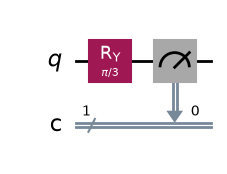

Predicted probabilities: P(0) = 75%, P(1) = 25%
Measured counts: {'1': 28, '0': 72}
Circuit B: 1 favored


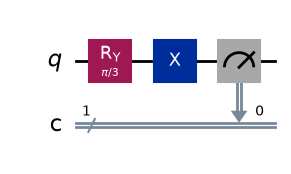

Predicted probabilities: P(0) = 25%, P(1) = 75%
Measured counts: {'1': 74, '0': 26}


In [5]:
def run_case(name, flip=False):
    circuit = QuantumCircuit(1, 1)
    circuit.ry(3.141592653589793 / 3, 0)  # predicts P(1) = 0.25
    if flip:
        circuit.x(0)
    circuit.measure(0, 0)
    counts = StatevectorSampler().run([circuit], shots=SHOTS).result()[0].data.c.get_counts()
    print(name)
    display(circuit.draw(output="mpl"))
    print("Predicted probabilities: P(0) = 75%, P(1) = 25%" if not flip else
          "Predicted probabilities: P(0) = 25%, P(1) = 75%")
    print("Measured counts:", counts)
    return counts

zero_favored = run_case("Circuit A: 0 favored")
one_favored = run_case("Circuit B: 1 favored", flip=True)


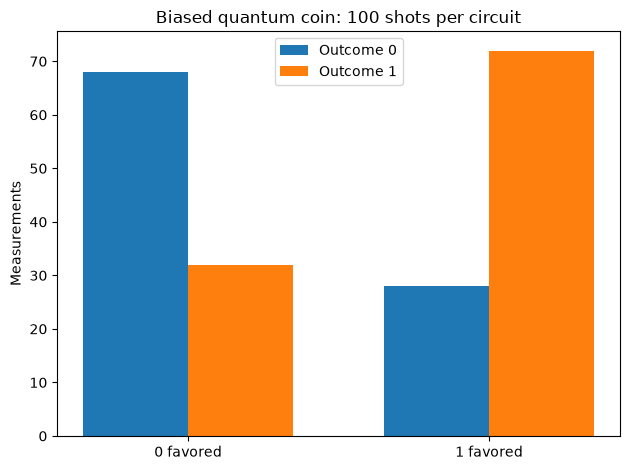

In [3]:
fig, ax = plt.subplots()
labels = ["0 favored", "1 favored"]
for i, outcome in enumerate(["0", "1"]):
    ax.bar([j + (i - 0.5) * 0.35 for j in range(2)],
           [counts.get(outcome, 0) for counts in [zero_favored, one_favored]],
           width=0.35, label=f"Outcome {outcome}")
ax.set_xticks(range(2), labels)
ax.set_ylabel("Measurements")
ax.set_title("Biased quantum coin: 100 shots per circuit")
ax.legend()
plt.tight_layout()
plt.show()


## Challenge question

Quantum gates change the probability amplitudes of the `|0⟩` and `|1⟩` parts of a qubit's state. The measurement probabilities are the squared magnitudes of those amplitudes. The RY rotation sets the bias, while X swaps the two probabilities.
